# Reduction audit: which methods actually produce a QUBO?

We apply every reduction method — the **12 quadratization baselines**, **FerQ**, and **FerQ-Bc** —
to **100 random mixed-sign HOBO** instances and measure two things:

1. **Does the output become a QUBO?** (all terms degree $\le 2$).
2. **High-order-term statistics:** how many degree-$\ge 3$ terms each method leaves.

The point: among the transformations, only **Rosenberg's substitution** and **FerQ-Bc** guarantee a
complete QUBO for *arbitrary sign*. The NTR-/PTR-/FGBZ- families are **sign-restricted** (they only
fully reduce terms of one sign), DeducReduc/PairwiseCovers are conditional, and **FerQ is
degree-preserving** — an exact reformulation that reduces no term. So \S4's comparison is among
*energy-transformation* methods, not among QUBO encoders.


## 0. Setup

In [10]:
import sys, os
import numpy as np
import pandas as pd
sys.path.insert(0, os.path.abspath('.'))
from reducers import (HOBO, FERQ, DeducReduc, NTR_KZFD, NTR_ABCG, NTR_ABCG2, NTR_GBP,
                      PTR_Ishikawa, PTR_KZ, PTR_GBP, ReductionBySubstitution,
                      FGBZ_Negative, FGBZ_Positive, PairwiseCovers)
from ferqbc_encoder import ferqbc_encode
try:
    import matplotlib.pyplot as plt; HAVE_PLT = True
except Exception:
    HAVE_PLT = False

N_INST, N, N_HIGH, DEG_MIN, DEG_MAX, SEED = 100, 20, 16, 3, 16, 12345

# 12 baselines: name -> (class, declared sign, declared degree)
BASELINES = {
    "Rosenberg":      (ReductionBySubstitution, "any",      "any"),
    "DeducReduc":     (DeducReduc,              "any",      "any"),
    "NTR_KZFD":       (NTR_KZFD,                "negative", "any"),
    "NTR_ABCG":       (NTR_ABCG,                "negative", "any"),
    "NTR_ABCG2":      (NTR_ABCG2,               "negative", "any"),
    "NTR_GBP":        (NTR_GBP,                 "negative", "cubic"),
    "PTR_Ishikawa":   (PTR_Ishikawa,            "positive", "any"),
    "PTR_KZ":         (PTR_KZ,                  "positive", "cubic"),
    "PTR_GBP":        (PTR_GBP,                 "positive", "cubic"),
    "FGBZ_Negative":  (FGBZ_Negative,           "negative", "any"),
    "FGBZ_Positive":  (FGBZ_Positive,           "positive", "any"),
    "PairwiseCovers": (PairwiseCovers,          "any",      "any"),
}
METHODS = ["FerQ-Bc", "Rosenberg"] + [m for m in BASELINES if m != "Rosenberg"] + ["FerQ"]
SIGN = {"FerQ": "any", "FerQ-Bc": "any", **{k: v[1] for k, v in BASELINES.items()}}
DEGH = {"FerQ": "preserves", "FerQ-Bc": "any", **{k: v[2] for k, v in BASELINES.items()}}

def random_hobo(rng):
    "Mixed-sign HOBO: N_HIGH high-order monomials (degree DEG_MIN..DEG_MAX) + N quadratics."
    terms = {}
    for _ in range(N_HIGH):
        d = int(rng.integers(DEG_MIN, DEG_MAX + 1))
        S = frozenset(rng.choice(N, size=d, replace=False).tolist())
        terms[S] = terms.get(S, 0.0) + float(rng.integers(-9, 10) or 1)     # mixed sign
    for _ in range(N):
        S = frozenset(rng.choice(N, size=2, replace=False).tolist())
        terms[S] = terms.get(S, 0.0) + float(rng.integers(-5, 6) or 1)
    return HOBO({k: v for k, v in terms.items() if abs(v) > 1e-12}, n_vars=N)

def reduce_terms(name, h):
    "Return (output_terms, n_aux) for the method's reduction of h."
    if name == "FerQ-Bc":
        out, na = ferqbc_encode(h); return out.terms, na
    if name == "FerQ":                       # exact reformulation; degree-preserving
        qr = FERQ(max_degree=15)(h.copy()); return qr.qubo.terms, qr.n_aux
    qr = BASELINES[name][0]()(h.copy()); return qr.qubo.terms, qr.n_aux

print("methods:", METHODS)

methods: ['FerQ-Bc', 'Rosenberg', 'DeducReduc', 'NTR_KZFD', 'NTR_ABCG', 'NTR_ABCG2', 'NTR_GBP', 'PTR_Ishikawa', 'PTR_KZ', 'PTR_GBP', 'FGBZ_Negative', 'FGBZ_Positive', 'PairwiseCovers', 'FerQ']


## 1. Generate 100 random mixed-sign HOBO and apply every method

In [11]:
rng = np.random.default_rng(SEED)
insts = [random_hobo(rng) for _ in range(N_INST)]
in_ho = np.array([sum(1 for t in h.terms if len(t) >= 3) for h in insts], float)   # input high-order terms
print("instances: %d  (n=%d, mean input high-order terms=%.1f, mean input degree=%.1f)"
      % (N_INST, N, in_ho.mean(), np.mean([h.degree for h in insts])))

S = {m: dict(qubo=[], aux=[], res=[], odeg=[], err=0) for m in METHODS}
for h in insts:
    for m in METHODS:
        try:
            terms, na = reduce_terms(m, h)
        except Exception:
            S[m]["err"] += 1; continue
        odeg = max((len(t) for t in terms), default=0)
        S[m]["qubo"].append(1.0 if odeg <= 2 else 0.0); S[m]["aux"].append(float(na))
        S[m]["res"].append(float(sum(1 for t in terms if len(t) >= 3))); S[m]["odeg"].append(float(odeg))

def agg(m):
    q = np.array(S[m]["qubo"]); a = np.array(S[m]["aux"]); r = np.array(S[m]["res"]); o = np.array(S[m]["odeg"])
    red = np.mean(1.0 - r / np.where(in_ho > 0, in_ho, 1)) if len(r) else 0.0
    return dict(qrate=100*q.mean(), aux=a.mean(), res_m=r.mean(), res_s=r.std(),
                odeg=o.mean(), red=100*red, err=S[m]["err"])
A = {m: agg(m) for m in METHODS}
print("done (errors:", {m: A[m]["err"] for m in METHODS if A[m]["err"]} or "none", ")")

instances: 100  (n=20, mean input high-order terms=16.0, mean input degree=15.5)
done (errors: none )


## 2. Which methods produce a complete QUBO?

`QUBO rate` = fraction of the 100 instances whose output is fully degree $\le 2$.

In [12]:
df1 = pd.DataFrame([{
    "method": m, "sign": SIGN[m], "degree": DEGH[m],
    "QUBO rate": "%.0f%%" % A[m]["qrate"], "mean n_aux": round(A[m]["aux"], 1),
} for m in METHODS]).set_index("method")
df1

,sign,degree,QUBO rate,mean n_aux
method,,,,
FerQ-Bc,any,any,100%,90.3
Rosenberg,any,any,100%,118.0
DeducReduc,any,any,0%,0.0
NTR_KZFD,negative,any,0%,7.7
NTR_ABCG,negative,any,0%,7.7
NTR_ABCG2,negative,any,0%,7.7
NTR_GBP,negative,cubic,0%,0.6
PTR_Ishikawa,positive,any,0%,32.7
PTR_KZ,positive,cubic,0%,0.6


## 3. High-order-term statistics

`residual HO` = mean number of degree-$\ge 3$ terms left in the output (input has %d on average);
`HO reduced` = fraction of high-order terms removed (negative $\Rightarrow$ the method *adds*
high-order terms).

In [13]:
df2 = pd.DataFrame([{
    "method": m, "in HO terms": round(in_ho.mean(), 1),
    "residual HO": "%.2f ± %.2f" % (A[m]["res_m"], A[m]["res_s"]),
    "mean out-degree": round(A[m]["odeg"], 2), "HO reduced": "%.0f%%" % A[m]["red"],
} for m in METHODS]).set_index("method")
df2

,in HO terms,residual HO,mean out-degree,HO reduced
method,,,,
FerQ-Bc,16.0,0.00 ± 0.00,2.00,100%
Rosenberg,16.0,0.00 ± 0.00,2.00,100%
DeducReduc,16.0,10.80 ± 2.89,14.57,32%
NTR_KZFD,16.0,8.33 ± 1.93,14.56,48%
NTR_ABCG,16.0,8.33 ± 1.93,14.56,48%
NTR_ABCG2,16.0,8.33 ± 1.93,14.56,48%
NTR_GBP,16.0,15.39 ± 0.75,15.52,4%
PTR_Ishikawa,16.0,7.67 ± 1.93,14.78,52%
PTR_KZ,16.0,15.36 ± 0.77,15.52,4%


## 4. Plots

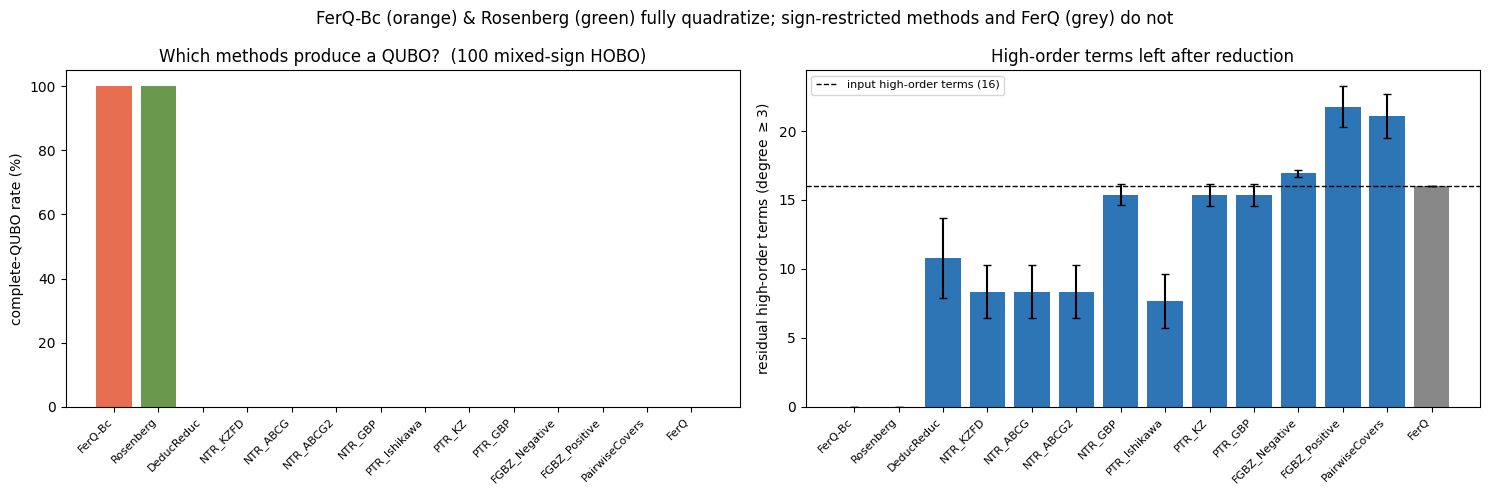

In [14]:
if HAVE_PLT:
    order = METHODS
    col = ["#E76F51" if m == "FerQ-Bc" else ("#6A994E" if m == "Rosenberg" else
           ("#888888" if m == "FerQ" else "#2E75B6")) for m in order]
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    x = np.arange(len(order))
    ax[0].bar(x, [A[m]["qrate"] for m in order], color=col)
    ax[0].set_ylabel("complete-QUBO rate (%)"); ax[0].set_ylim(0, 105)
    ax[0].set_title("Which methods produce a QUBO?  (100 mixed-sign HOBO)")
    ax[0].set_xticks(x); ax[0].set_xticklabels(order, rotation=45, ha="right", fontsize=8)
    ax[1].bar(x, [A[m]["res_m"] for m in order], yerr=[A[m]["res_s"] for m in order], capsize=3, color=col)
    ax[1].axhline(in_ho.mean(), ls="--", color="k", lw=1, label="input high-order terms (%.0f)" % in_ho.mean())
    ax[1].set_ylabel("residual high-order terms (degree $\\geq 3$)")
    ax[1].set_title("High-order terms left after reduction"); ax[1].legend(fontsize=8)
    ax[1].set_xticks(x); ax[1].set_xticklabels(order, rotation=45, ha="right", fontsize=8)
    fig.suptitle("FerQ-Bc (orange) & Rosenberg (green) fully quadratize; sign-restricted methods "
                 "and FerQ (grey) do not", fontsize=12)
    fig.tight_layout(); plt.show()